In [1]:
import sys
sys.path.append('/lhome/ific/c/ccortesp/Analysis/')

from libs import crudo

from   iminuit import Minuit
from   iminuit.cost import LeastSquares
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from   scipy.optimize import curve_fit
from   scipy.signal import find_peaks
import yaml

# Styling Plot
# crudo.pt.papers_plot_style()
crudo.pt.ccortesp_plot_style()
# PRELIM_LOGO = np.asarray(Image.open('/lhome/ific/c/ccortesp/Analysis/images/next_logo_preliminary.png'))

%matplotlib inline
%load_ext autoreload
%autoreload 2

# Runs Configuration

In [6]:
RUNS_TO_CHECK = [14739, 16122, 16123]
EXTRA_TAG = None      # Options: None, '20260727', 'prod_cuts'
CRITERIA  = 'Xe_v1'      # Options: 'Ar', 'Xe', 'XevN'

RUNS_INFO_FILENAME = "/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/utilities/runs_information.csv"
BASE_PATH = '/lhome/ific/c/ccortesp/Data/Cmmssnng/h5/'

In [7]:
RUNS_INFO_DF = pd.read_csv(RUNS_INFO_FILENAME, index_col="run_number").reset_index()
RUNS_INFO_DF = RUNS_INFO_DF[RUNS_INFO_DF["run_number"].isin(RUNS_TO_CHECK)].copy()
RUNS_INFO_DF

,run_number,pressure,cath_voltage,gate_voltage,duration,OK,LOST,isotope
2,14739,3.956,22997.3,7501.1,87138.0,2576630.0,2334343.0,Xe
18,16122,8.869,32997.0,12001.5,69722.0,2672089.0,10742152.0,Xe
19,16123,8.867,32997.0,9401.6,NaN,NaN,NaN,Xe


# Selected Data

In [8]:
SEL_DICT = {}

print('Loading selected data for:')
for run_id in RUNS_INFO_DF['run_number']:

    # Construct a clean, descriptive dictionary key
    key = f"{run_id}_v{EXTRA_TAG}" if EXTRA_TAG is not None else f"{run_id}"
    print(f"  - Run {key}")

    # Load and assign the data
    doro_df = pd.read_hdf(os.path.join(BASE_PATH, 'run_' + key + '_selected_' + CRITERIA + '.h5'), key='DST/Events')
    soph_df = pd.read_hdf(os.path.join(BASE_PATH, 'run_' + key + '_selected_' + CRITERIA + '.h5'), key='RECO/Events')

    SEL_DICT[key] = {}
    SEL_DICT[key]['doro_df'] = doro_df
    SEL_DICT[key]['soph_df'] = soph_df

Loading selected data for:
  - Run 14739
  - Run 16122
  - Run 16123


Construct the _active volume_ mask to avoid the cathode

In [9]:
EXTRA_INFO = {}
ALPHA_CUT = 1200    # In [PE]

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    cath_lim = crudo.tf.get_cathode_limit(doro_df, n_bins=80, step_back=1)
    # cath_lim = doro_df['DT'].max()
    z_mask    = (doro_df['DT'] >= 0) & (doro_df['DT'] < cath_lim)
    cath_mask = (doro_df['DT'] >= cath_lim)

    alpha_mask = (doro_df['S1e_corr'] >= ALPHA_CUT)

    EXTRA_INFO[key] = { 'cath_lim': cath_lim, 'AV_Z_mask': z_mask, 'cath_mask': cath_mask, 'alpha_mask': alpha_mask }


Run 14739:
Cathode limit = 1311.34 μs

Run 16122:
Cathode limit = 1537.11 μs

Run 16123:
Cathode limit = 1469.11 μs


## Radial


Run 14739:
  - R² = [1.60, 237345.68] mm²


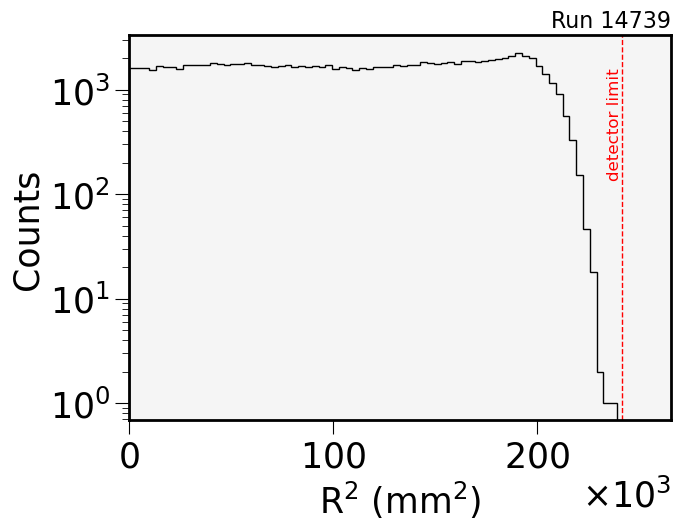


Run 16122:
  - R² = [4.77, 274289.76] mm²


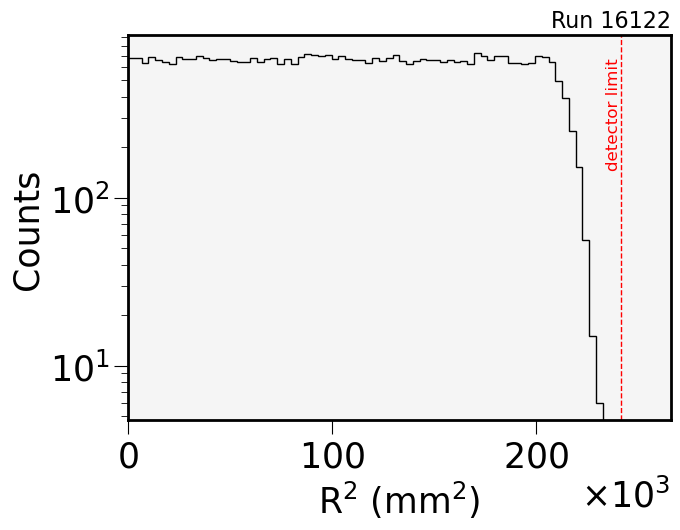


Run 16123:
  - R² = [6.43, 236767.67] mm²


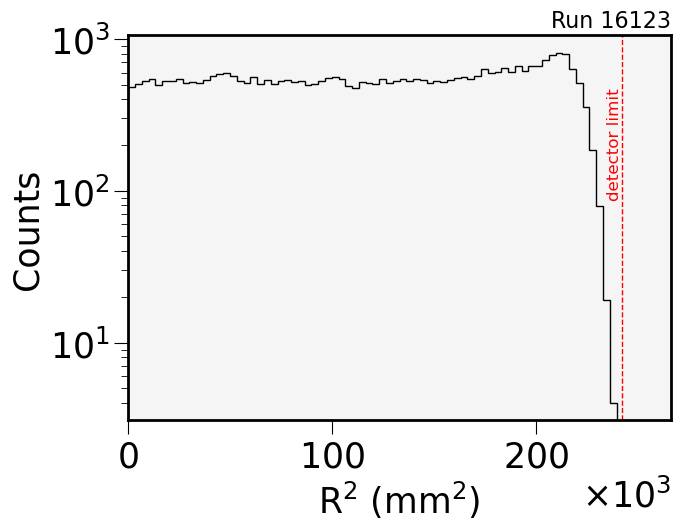

In [13]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    R2 = doro_df['X']**2 + doro_df['Y']**2

    # Mask
    mask = EXTRA_INFO[key]['alpha_mask']
    if mask is not None:
        R2 = R2[mask]

    print(f"  - R² = [{R2.min():.2f}, {R2.max():.2f}] mm²")

    # Histogram
    counts, bins, _ = plt.hist(R2, bins=80, range=(0, 1.1*crudo.pt.N100_rad**2), histtype='step', color='black', lw=1.0)

    # Plot
    plt.xlabel('R$^{2}$ (mm$^{2}$)')
    plt.ylabel('Counts')
    plt.yscale('log')
    plt.xlim(bins[0], bins[-1])
    plt.ticklabel_format(axis='x', style='sci', scilimits=(3, 3))
    plt.title(f'Run {key}', loc='right', fontsize=16)
    # Radial line
    plt.axvline(x=crudo.pt.N100_rad**2, c='red', ls='--', lw=1)
    plt.text(crudo.pt.N100_rad**2, counts[0], 'detector limit', c='red', va='top',  ha='right',  rotation=90, fontsize=12)

    plt.gca().set_facecolor("whitesmoke")
    
    # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/R_dist_run_{key}.pdf')
    plt.show()

# Event-level

### Active Volume

In [10]:
# for key in SEL_DICT.keys():
#     print(f"\nRun {key}:")
#     doro_df = SEL_DICT[key]['doro_df']

#     # Agrupar por intervalos de 50 µs en DT
#     dt_bins = np.arange(0, doro_df['DT'].max() + 50, 300)
#     doro_df['DT_bin'] = pd.cut(doro_df['DT'], bins=dt_bins)

#     # Iterar sobre cada intervalo de DT
#     for dt_bin, group in doro_df.groupby('DT_bin'):
#         if group.empty:
#             continue

#         print(f"  DT range: {dt_bin}")

#         # Variables
#         X = group['X']
#         Y = group['Y']

#         # Map
#         xy_map, ex, ey = crudo.pt.mapping(X, Y, bin_scale=4, max_limit=crudo.pt.N100_rad, pos=True, norm=True)
#         xy_map = np.ma.masked_where(xy_map == 0, xy_map)

#         # Plot
#         plt.pcolormesh(ex, ey, xy_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.6, vmax=1.4)
#         cbar = plt.colorbar(label='A. U.')
#         cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
#         plt.xlabel('X (mm)')
#         plt.ylabel('Y (mm)')
#         plt.title(f'Run {key} | DT: {dt_bin}', loc='center', fontsize=12)

#         plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
#         plt.gca().set_aspect('equal', adjustable='box')
#         plt.gca().set_facecolor("whitesmoke")
        # plt.show()


Run 14739:


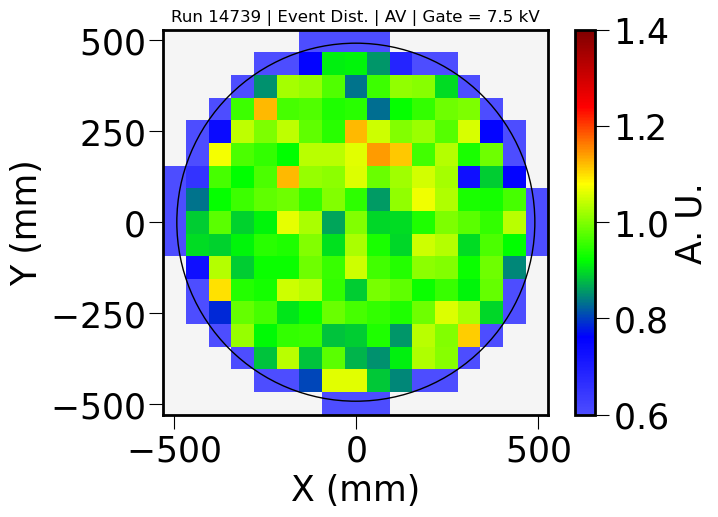


Run 16122:


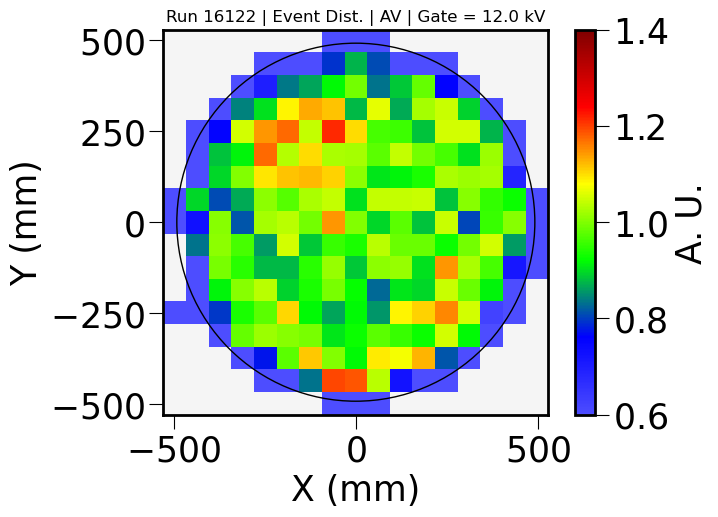


Run 16123:


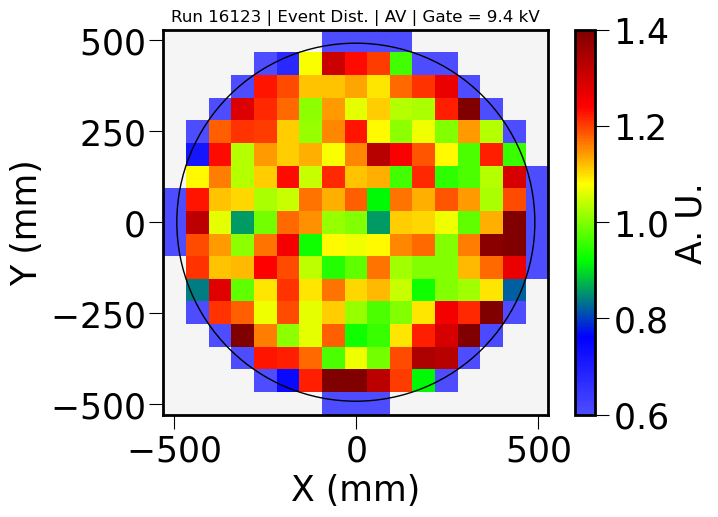

In [14]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']
    gate_volt = RUNS_INFO_DF.loc[RUNS_INFO_DF['run_number'] == int(key.split('_')[0]), 'gate_voltage'].values[0] / 1e3

    # Variables    
    X = doro_df['X']
    Y = doro_df['Y']

    # Masking
    mask = (EXTRA_INFO[key]['AV_Z_mask']) & (EXTRA_INFO[key]['alpha_mask'])
    if mask is not None:
        X = X[mask]
        Y = Y[mask]

    # Map
    xy_map, ex, ey = crudo.pt.mapping(X, Y, bin_scale=4, max_limit=crudo.pt.N100_rad, pos=True, norm=True)
    xy_map         = np.ma.masked_where(xy_map==0, xy_map)

    # Plot
    plt.pcolormesh(ex, ey, xy_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.6, vmax=1.4)
    cbar = plt.colorbar(label='A. U.')
    cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    # plt.title (f'Run {key} | Event Dist.', loc='center', fontsize=12) 
    plt.title (f'Run {key} | Event Dist. | AV | Gate = {gate_volt:.1f} kV', loc='center', fontsize=12)

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/events_dist_run_{key}.pdf')
    plt.show()


Run 14739:


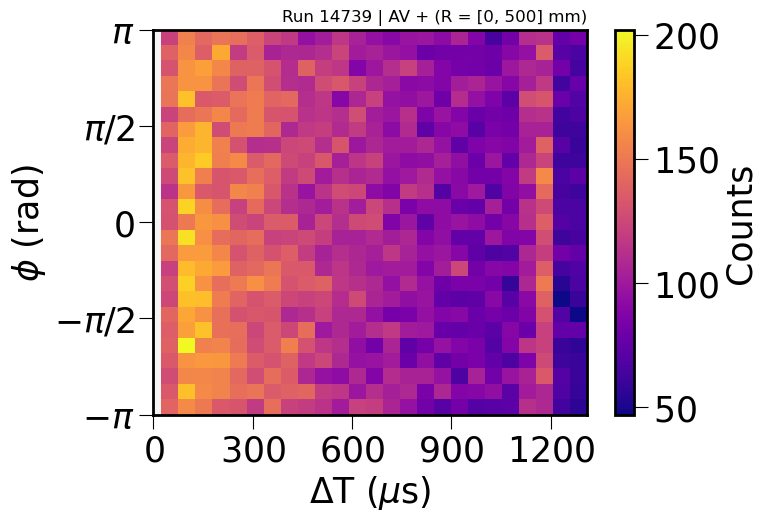


Run 16122:


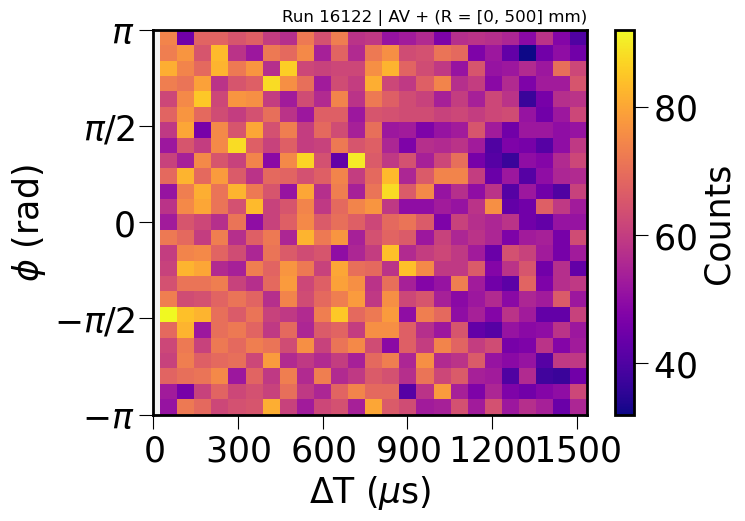


Run 16123:


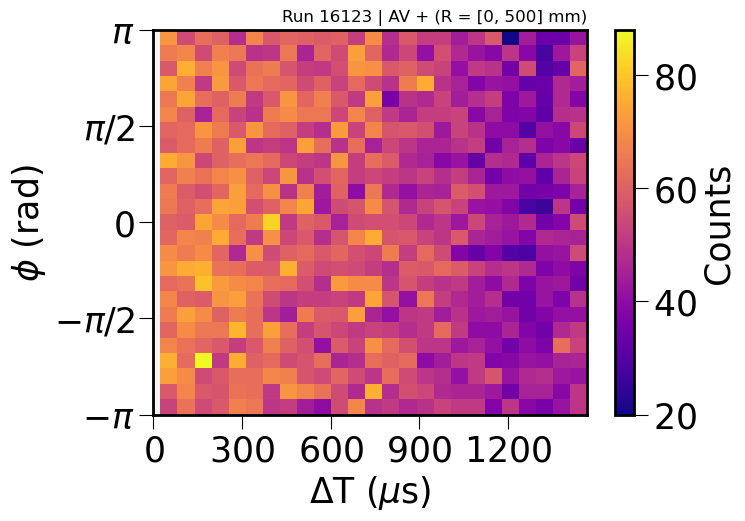

In [12]:
rad_max = 500
rad_min = 0
n_bins = 25

for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables
    DT = doro_df['DT']
    X = doro_df['X'];   Y = doro_df['Y']
    phi = np.arctan2(Y, X)

    # Masking
    mask = (EXTRA_INFO[key]['AV_Z_mask'])
    # mask = (R <= 200)
    # mask = None
    if mask is not None:
        phi = phi[mask]
        DT = DT[mask]

    # 2D Histogram
    phi_dt_map, ex, ey = np.histogram2d(DT, phi, bins=[n_bins, n_bins])
    phi_dt_map         = np.ma.masked_where(phi_dt_map==0, phi_dt_map)

    # Plot
    plt.pcolormesh(ex, ey, phi_dt_map.T, cmap='plasma', shading='auto')
    plt.colorbar(label='Counts')
    plt.xlabel('$\Delta$T ($\mu$s)')
    plt.ylabel(r'$\phi$ (rad)')
    plt.xlim(ex[0], ex[-1])
    # plt.ylim(-np.pi, np.pi)
    plt.xticks(np.arange(0, DT.max(), 300))
# Set x-ticks as multiples of π
    ticks = np.arange(-np.pi, np.pi + 0.1, np.pi / 2)
    tick_labels = [r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$']
    plt.yticks(ticks, tick_labels)
    # plt.ticklabel_format(axis='y', style='sci', scilimits=(3, 3))
    plt.title (f'Run {key} | AV + (R = [{rad_min}, {rad_max}] mm)', loc='right', fontsize=12)

    # Lines
    # plt.axvline(x=150, c='gray', ls='--', lw=2)
    # plt.axhline(y=12e3, c='black', ls='--', lw=1.5)

    plt.gca().set_facecolor("whitesmoke")
    plt.show()

### Cathode


Run 16105:


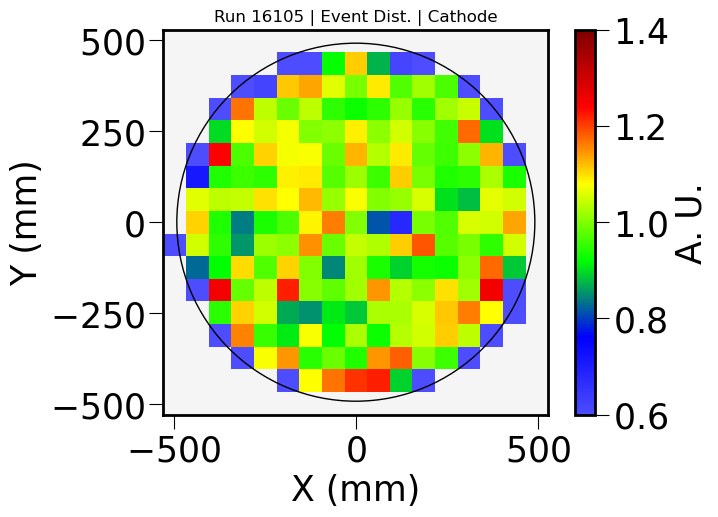


Run 16114:


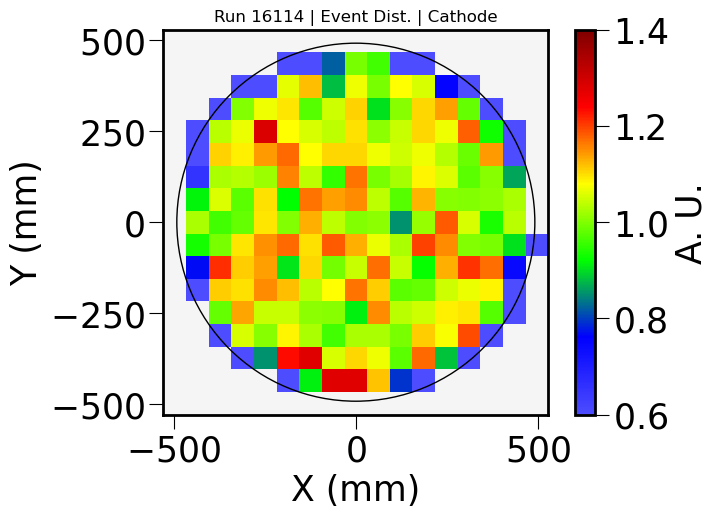


Run 16116:


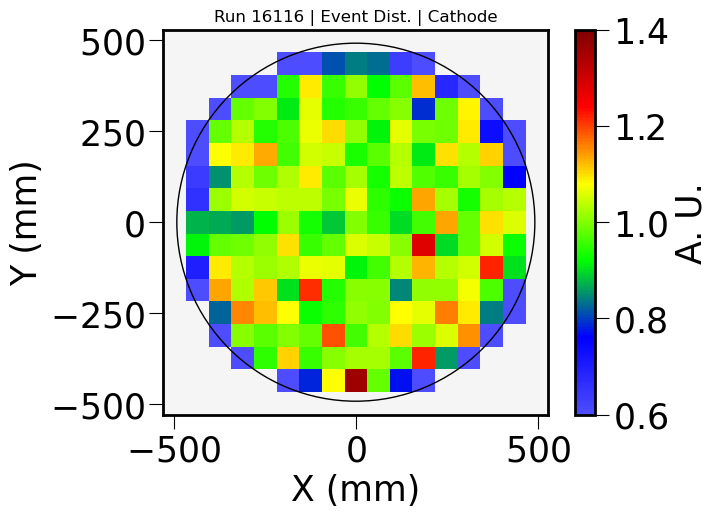


Run 16120:


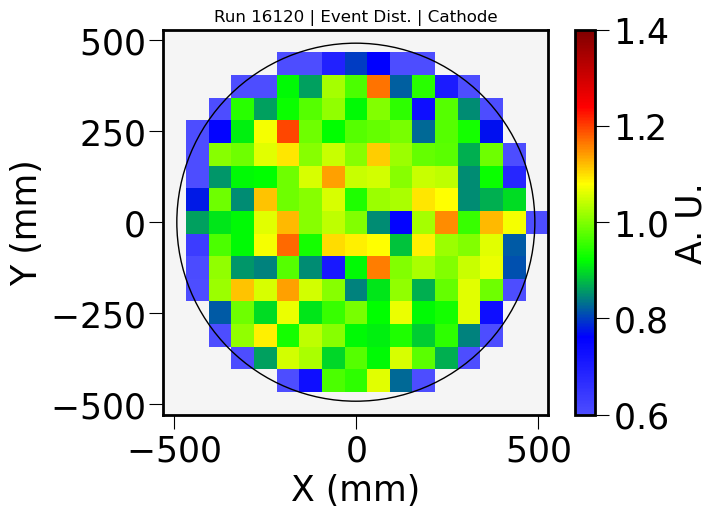

In [17]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    doro_df = SEL_DICT[key]['doro_df']

    # Variables    
    X = doro_df['X']
    Y = doro_df['Y']

    # Masking
    mask = (EXTRA_INFO[key]['cath_mask'])
    if mask is not None:
        X = X[mask]
        Y = Y[mask]

    # Map
    xy_map, ex, ey = crudo.pt.mapping(X, Y, bin_scale=4, max_limit=crudo.pt.N100_rad, pos=True, norm=True)
    xy_map         = np.ma.masked_where(xy_map==0, xy_map)

    # Plot
    plt.pcolormesh(ex, ey, xy_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.6, vmax=1.4)
    cbar = plt.colorbar(label='A. U.')
    cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    # plt.title (f'Run {key} | Event Dist.', loc='center', fontsize=12) 
    plt.title (f'Run {key} | Event Dist. | Cathode', loc='center', fontsize=12)

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    # plt.savefig(f'/lhome/ific/c/ccortesp/Analysis/NEXT-100/Cmmssnng/images/events_dist_run_{key}.pdf')
    plt.show()

# Hit-level

### Active Volume


Run 14739:


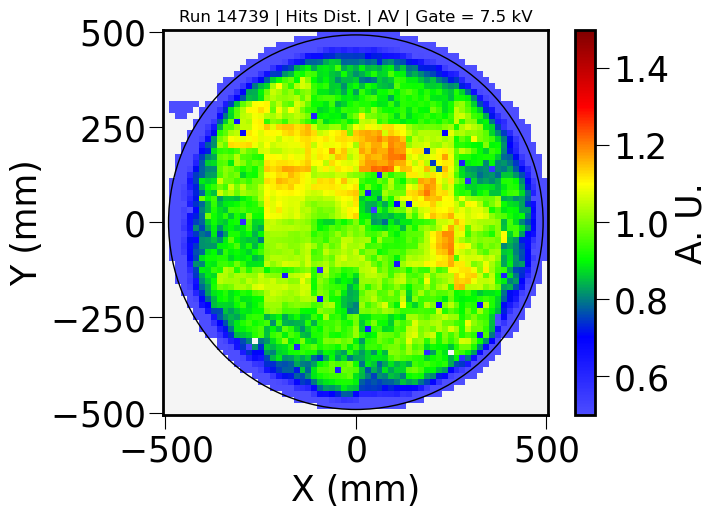


Run 16122:


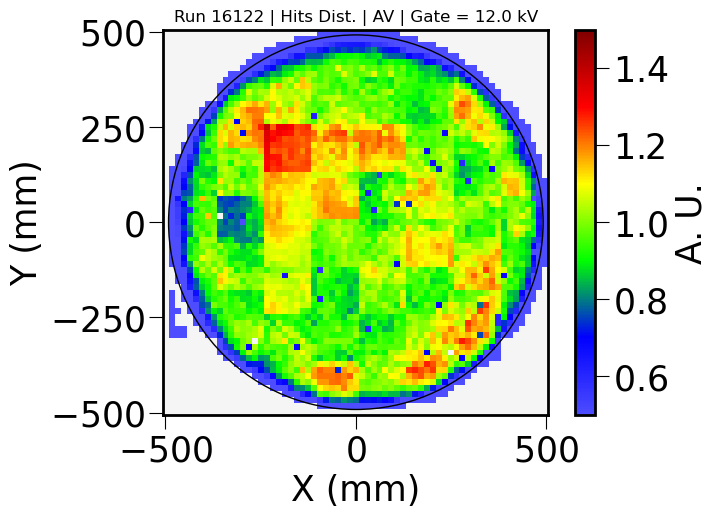


Run 16123:


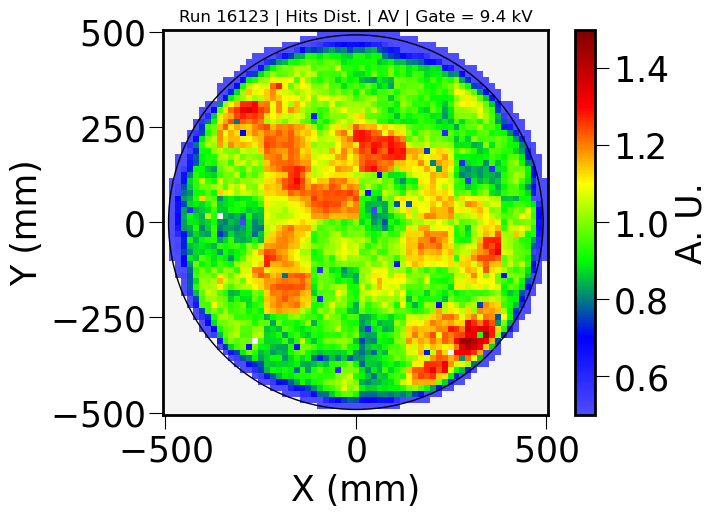

In [16]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    soph_df = SEL_DICT[key]['soph_df']
    gate_volt = RUNS_INFO_DF.loc[RUNS_INFO_DF['run_number'] == int(key.split('_')[0]), 'gate_voltage'].values[0] / 1e3

    # Variables    
    X = soph_df['X']
    Y = soph_df['Y']
    Z = soph_df['Z']

    # Masking
    mask = (Z >= 0) & (Z < EXTRA_INFO[key]['cath_lim'])
    X_mask = X[mask]
    Y_mask = Y[mask]

    # Map
    xy_map, ex, ey = crudo.pt.mapping(X_mask, Y_mask, bin_scale=1, max_limit=crudo.pt.N100_rad, pos=True, norm=True)
    xy_map         = np.ma.masked_where(xy_map==0, xy_map)

    # Plot
    plt.pcolormesh(ex, ey, xy_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = plt.colorbar(label='A. U.')
    cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Hits Dist. | AV | Gate = {gate_volt:.1f} kV', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()

### Cathode


Run 16105:


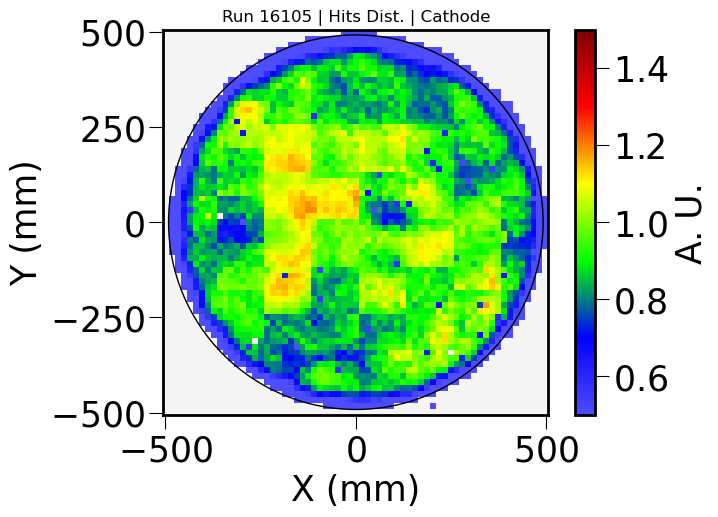


Run 16114:


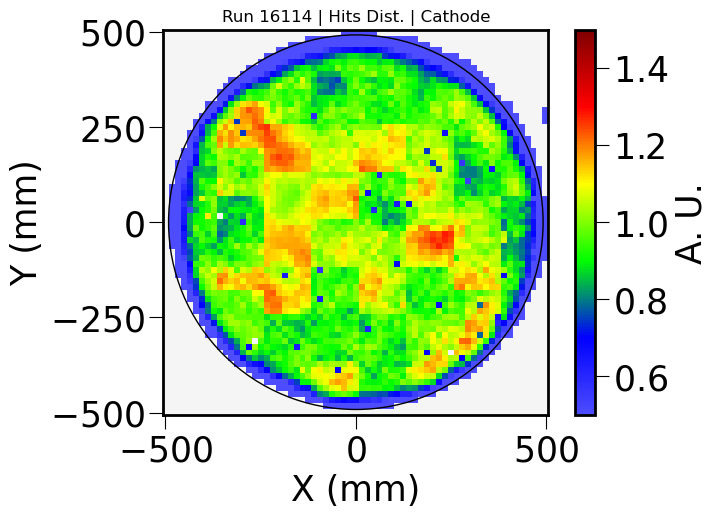


Run 16116:


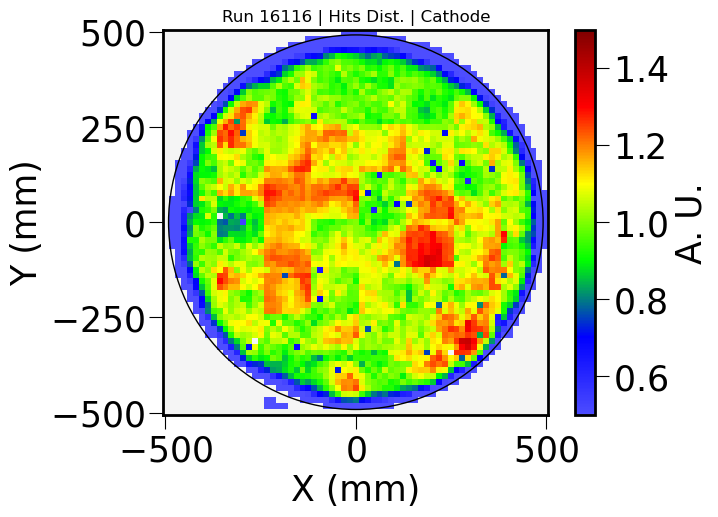


Run 16120:


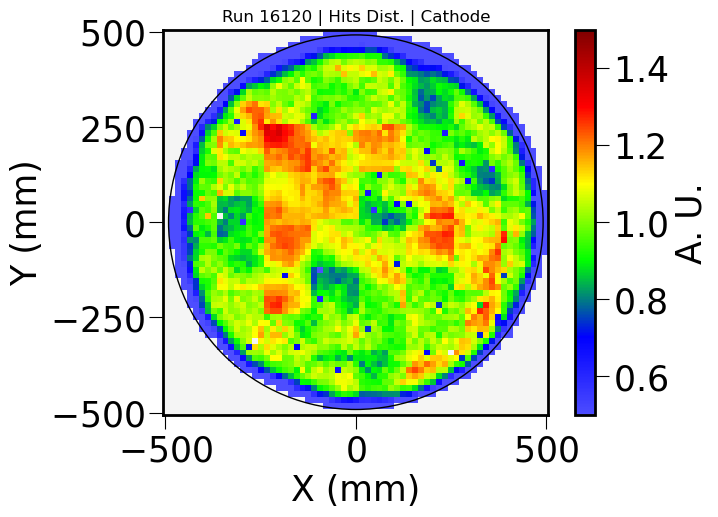

In [18]:
for key in SEL_DICT.keys():

    print(f"\nRun {key}:")
    soph_df = SEL_DICT[key]['soph_df']

    # Variables    
    X = soph_df['X']
    Y = soph_df['Y']
    Z = soph_df['Z']

    # Masking
    mask = (Z >= EXTRA_INFO[key]['cath_lim'])
    X_mask = X[mask]
    Y_mask = Y[mask]

    # Map
    xy_map, ex, ey = crudo.pt.mapping(X_mask, Y_mask, bin_scale=1, max_limit=crudo.pt.N100_rad, pos=True, norm=True)
    xy_map         = np.ma.masked_where(xy_map==0, xy_map)

    # Plot
    plt.pcolormesh(ex, ey, xy_map.T, cmap=crudo.pt.custom_hsv, shading='auto', vmin=0.5, vmax=1.5)
    cbar = plt.colorbar(label='A. U.')
    cbar.set_ticks([0.6, 0.8, 1.0, 1.2, 1.4])
    plt.xlabel('X (mm)')
    plt.ylabel('Y (mm)')
    plt.title (f'Run {key} | Hits Dist. | Cathode', loc='center', fontsize=12) 

    plt.gca().add_patch(crudo.pt.plot_circle(crudo.pt.N100_rad))
    plt.gca().set_aspect('equal', adjustable='box')
    plt.gca().set_facecolor("whitesmoke")
    plt.show()